# Mobility Trajectory Data Flow and Modeling
Dr. Jorge Celis
October,2024

## Outline

Train a Gravity model in Santa Barbara to predict flows in California

1. Download checkin data and create a TrajDataFrame
2. Create square tessellations for the two cities
3. Compute the relevance of each tile
4. Create FlowDataFrames aggregating TrajDataFrames
5. Compute the total number of trips from each tile

Fit a singly-constrained Gravity using trips in San Barbara

Use the fitted model to predict flows in California or a given city

Qualitative evaluation: visualise the performance of the model against a baseline random model

Quantitative evaluation: compute performance metrics

# 1. Libraries

In [3]:
import skmob
from skmob.utils import utils, constants
from skmob.tessellation import tilers
from skmob.utils.plot import plot_gdf

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import folium
from folium.plugins import HeatMap
import matplotlib as mpl
import matplotlib.pyplot as plt

# Importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from glob import glob
from tqdm import tqdm
import plotly.express as px
import os

# scikit-mobility imports
from skmob.core.trajectorydataframe import TrajDataFrame
from skmob.preprocessing import detection
from skmob.measures import individual

# Geospatial imports
import geopandas as gpd
import geoplot as gplt

# Math and statistics libraries
import math
import scipy
from scipy import stats

# Map plotting libraries
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import Polygon, box

# Other useful imports
import wget
from census import Census
from us import states
import netCDF4 as nc
from datetime import datetime
import sklearn
from sklearn import ensemble
from sklearn.neighbors import KernelDensity
from sklearn.metrics import mean_squared_error
import xarray as xr

# 2. Data
## 2.1. Spatial and ancillary data

In [4]:
# Load California Counties and ZIP codes GeoJSON
counties = gpd.read_file("https://raw.githubusercontent.com/codeforgermany/click_that_hood/master/public/data/california-counties.geojson")
zip_codes = gpd.read_file("https://raw.githubusercontent.com/OpenDataDE/State-zip-code-GeoJSON/master/ca_california_zip_codes_geo.min.json")

california_url = "https://raw.githubusercontent.com/codeforgermany/click_that_hood/master/public/data/california-counties.geojson"
california_shape = gpd.read_file(california_url)

# Display the first few rows of the GeoDataFrame
print(zip_codes.head())

  STATEFP10 ZCTA5CE10  GEOID10 CLASSFP10 MTFCC10 FUNCSTAT10   ALAND10  \
0        06     94601  0694601        B5   G6350          S   8410939   
1        06     94501  0694501        B5   G6350          S  20539466   
2        06     94560  0694560        B5   G6350          S  35757865   
3        06     94587  0694587        B5   G6350          S  51075108   
4        06     94580  0694580        B5   G6350          S   8929836   

   AWATER10   INTPTLAT10    INTPTLON10 PARTFLG10  \
0    310703  +37.7755447  -122.2187049         N   
1   9005303  +37.7737968  -122.2781230         N   
2     60530  +37.5041413  -122.0323587         N   
3         0  +37.6031556  -122.0186382         N   
4     17052  +37.6757312  -122.1330170         N   

                                            geometry  
0  POLYGON ((-122.22717 37.79197, -122.22693 37.7...  
1  POLYGON ((-122.29181 37.76301, -122.30661 37.7...  
2  POLYGON ((-122.05499 37.5496, -122.05441 37.55...  
3  POLYGON ((-122.06515 37.6

## 2.2. Mobility data
### 2.2.1. Single day data download

In [5]:
dir_path = '/glade/u/home/jcelis/CAT/Data/Mobility/Veraset/2024/03/21/'
files = sorted(glob(dir_path + "*.parquet"))

In [21]:
data_list = []
for data_file in tqdm(files):
    data_list.append(pd.read_parquet(data_file)[['utc_timestamp', 'caid', 'id_type', 'latitude', 'longitude']])
data = pd.concat(data_list)

100%|██████████| 1024/1024 [13:29<00:00,  1.27it/s]


### 2.2.2. Multiple days and entire data download

In [6]:
# Define the base directory containing the daily folders
base_dir = '/glade/u/home/jcelis/CAT/Data/Mobility/Veraset/2024/'

#### The entire dataset

In [ ]:
# Use glob to recursively find all .parquet files in the subdirectories
files = sorted(glob(os.path.join(base_dir, "*/*/*.parquet")))

# Print the list of files
print(f"Found {len(files)} files:")
for file in files:
    print(file)

#### Specific dates

In [7]:
specific_days = ['03/21', '03/22']
files = []
for day in specific_days:
    files.extend(sorted(glob(os.path.join(base_dir, day, "*.parquet"))))

In [8]:
# Count the number of files in the list
num_files = len(files)

# Print the count
print(f"Total number of files: {num_files}")

Total number of files: 2048


## 2.2.3. Trajectory data frame

This trajectory data frame (TDF) is created from a list.

In [9]:
data_list = []
for data_file in tqdm(files):
    data_list.append(pd.read_parquet(data_file)[['utc_timestamp', 'caid', 'id_type', 'latitude', 'longitude']])
data = pd.concat(data_list)

100%|██████████| 2048/2048 [24:27<00:00,  1.40it/s]


In [61]:
from tqdm import tqdm  # Import tqdm for the progress bar

In [66]:
# Process each Parquet file
if files:
    print(f"Found {len(files)} files. Processing them...")

    for idx, file_path in enumerate(files):
        # Step 1: Read the Parquet file into a pandas DataFrame
        df = pd.read_parquet(file_path, engine='pyarrow')  # or engine='fastparquet'

        # Step 2: Rename columns to match the expected TrajDataFrame format
        df.rename(columns={'utc_timestamp': 'datetime', 'caid': 'user_id'}, inplace=True)

        # Ensure that 'datetime' is in the correct datetime format
        df['datetime'] = pd.to_datetime(df['datetime'])

        # Step 3: Create the TrajDataFrame
        tdf = skmob.TrajDataFrame(df, latitude='latitude', longitude='longitude', datetime='datetime', user_id='user_id')

        # Print detailed output for the first and last files
        if idx == 0:  # First file
            print(f"\n--- First File ({idx + 1}/{len(files)}): {file_path} ---")
            print(f"Number of records: {len(df)}")
            print(f"Time range: {df['datetime'].min()} to {df['datetime'].max()}")
            print(f"Unique users: {df['user_id'].nunique()}")
            print(df.head())  # Print the first few rows

        if idx == len(files) - 1:  # Last file
            print(f"\n--- Last File ({idx + 1}/{len(files)}): {file_path} ---")
            print(f"Number of records: {len(df)}")
            print(f"Time range: {df['datetime'].min()} to {df['datetime'].max()}")
            print(f"Unique users: {df['user_id'].nunique()}")
            print(df.head())  # Print the first few rows

else:
    print("No Parquet files found for the specified days.")

Found 2048 files. Processing them...

--- First File (1/2048): /glade/u/home/jcelis/CAT/Data/Mobility/Veraset/2024/03/21/part-00000-tid-1290147603924480478-ce0f3766-4de7-4d41-ab59-7cf28192c92f-206492-1-c000.gz.parquet ---
Number of records: 101160
Time range: 2024-03-21 00:00:01 to 2024-03-21 23:59:57
Unique users: 5930
             datetime                                            user_id  \
0 2024-03-21 14:42:01  29bbdd2f2e78c679ad5ecb443539232b24562a53ed5d85...   
1 2024-03-21 11:35:31  59ebdba1f7a2b73d438c1c4723a7d21bbb66f006bf9fae...   
2 2024-03-21 06:35:31  3b3e10940ebde058d7ba7c58b0c38d73ab7660c20fe418...   
3 2024-03-21 01:28:31  1b25aa0c09480c4de46e0528a3a904aa73f96335516ef8...   
4 2024-03-21 01:22:50  1b25aa0c09480c4de46e0528a3a904aa73f96335516ef8...   

  id_type   latitude    longitude horizontal_accuracy      ip_address  \
0    aaid   35.73825   -119.33738                 5.0  107.196.230.73   
1    idfa   33.88083   -117.59991                 8.0   172.58.27.136   
2 

In [67]:
#tdf = skmob.TrajDataFrame(df, latitude='latitude', longitude='longitude', datetime='utc_timestamp', user_id='caid')

In [68]:
# # List all files in the directory
# files = sorted(os.listdir(dir_path))

# # Filter for Parquet files
# parquet_files = [f for f in files if f.endswith('.parquet')]

# # Check if there are any Parquet files
# if parquet_files:
#     first_parquet_file = parquet_files[0]  # Get the first file from the list
#     file_path = os.path.join(base_dir, first_parquet_file)
    
#     # Step 1: Read the Parquet file into a pandas DataFrame
#     df = pd.read_parquet(file_path, engine='pyarrow')  # or engine='fastparquet'

#     # Step 2: Rename columns to match the expected TrajDataFrame format
#     df.rename(columns={'utc_timestamp': 'datetime', 'caid': 'user_id'}, inplace=True)

#     # Ensure that 'datetime' is in the correct datetime format
#     df['datetime'] = pd.to_datetime(df['datetime'])

#     # Step 3: Create the TrajDataFrame
#     tdf = skmob.TrajDataFrame(df, latitude='latitude', longitude='longitude', datetime='datetime', user_id='user_id')

#     # Print the first few rows of the TrajDataFrame
#     print(tdf.head())
# else:
#     print("No Parquet files found in the directory.")

In [70]:
print(tdf.head())
print('Points of the original trajectory:\t%s'%len(tdf))

             datetime                                                uid  \
0 2024-03-22 01:22:53  1cab6b6e26ffdc53c8c67bc9f53f35f82abd894f2f1e0f...   
1 2024-03-22 06:39:20  e6f7932e6994adc9da1862299cf7c9dc8c3df2dba62909...   
2 2024-03-22 09:33:52  bdc20bdad6a85597d0fecc710d90113e9c0f7052701b83...   
3 2024-03-22 09:09:26  616501b1357e2b9083cbf1cdfd82eaed13eca5bb6cfea8...   
4 2024-03-22 06:15:16  bdc20bdad6a85597d0fecc710d90113e9c0f7052701b83...   

  id_type        lat         lng horizontal_accuracy      ip_address  \
0    idfa  34.790920 -116.478940                 4.0    107.77.165.1   
1    idfa  35.167100 -118.336560                 7.0  107.77.227.206   
2    idfa  34.102627 -117.455605                10.0  100.43.234.131   
3    aaid  37.461970 -121.132150                11.0   107.242.121.6   
4    idfa  34.102600 -117.455680                11.0  100.43.234.131   

  iso_country_code                                     quality_fields  \
0               US  [(ping_sink_match

### Point of caution

The skmob package gets around 100K records, opening the question if this is aggregating them by user ID. However the number of users in a given day near 6k. On the other hand, the list (rows approach) results in 100M rows/ records. The line below uses the list approach. 

In [10]:
tdf_list_approach = TrajDataFrame(data, 
                    latitude="latitude", 
                    longitude="longitude",
                    datetime="utc_timestamp",
                    user_id="caid")

In [11]:
tdf_list_approach_sorted = tdf_list_approach.sort_values(by=["uid", "datetime"])

In [73]:
tdf_list_approach_sorted

,datetime,uid,id_type,lat,lng
17782,2024-03-22 02:12:33,0000033b8a8c11e83387dbdbc19c812d7f45938c8508f9...,idfa,38.43674,-121.44280
20892,2024-03-22 02:12:36,0000033b8a8c11e83387dbdbc19c812d7f45938c8508f9...,idfa,38.43677,-121.44283
94104,2024-03-22 13:11:47,00000561a63839dcf5213a299e60afafbb5c6c6536afa6...,idfa,37.18350,-121.77140
57666,2024-03-22 03:00:19,00000574824aabf29a2319e77e407a45382c2247a257e3...,idfa,33.66465,-117.17432
84908,2024-03-22 03:00:20,00000574824aabf29a2319e77e407a45382c2247a257e3...,idfa,33.66467,-117.17435
...,...,...,...,...,...
15652,2024-03-22 02:51:47,fffffe6bc17118860ef11d5bf59a725c69b640a91dd276...,idfa,33.65523,-117.66168
42010,2024-03-22 03:53:21,fffffe6bc17118860ef11d5bf59a725c69b640a91dd276...,idfa,33.65550,-117.66132
47425,2024-03-22 03:53:23,fffffe6bc17118860ef11d5bf59a725c69b640a91dd276...,idfa,33.65550,-117.66138
47589,2024-03-22 04:04:50,fffffe6bc17118860ef11d5bf59a725c69b640a91dd276...,idfa,33.65540,-117.66121


## 2.2.4. Detection of stops


In [31]:
from skmob.preprocessing import detection
# compute the stops for each individual in the TrajDataFrame
stdf = detection.stay_locations(tdf, stop_radius_factor=0.5, minutes_for_a_stop=20.0, spatial_radius_km=0.2, leaving_time=True)
# print a portion of the detected stops
print(stdf.head())

             datetime                                                uid  \
0 2024-03-21 04:28:12  0004b3da494e22ec745dbfa9fee74259c3a19e00e3f721...   
1 2024-03-21 05:03:04  0004b3da494e22ec745dbfa9fee74259c3a19e00e3f721...   
2 2024-03-21 10:19:09  003e40ecdcccf5b47b381ae532d0c1b450254afd067bcb...   
3 2024-03-21 10:41:38  003e40ecdcccf5b47b381ae532d0c1b450254afd067bcb...   
4 2024-03-21 02:07:52  0046294ebbc6fc282f97f826ab33a0cbb154d8835f6268...   

  id_type       lat         lng horizontal_accuracy       ip_address  \
0    idfa  34.06490 -118.259250                 7.0  103.161.158.183   
1    idfa  34.05222 -118.243680                 9.0  103.161.158.183   
2    aaid  35.00440 -118.159130                 7.0  107.196.124.143   
3    aaid  34.99603 -118.149660                14.0    107.77.229.25   
4    aaid  33.83015 -118.099515                 5.0   104.11.234.215   

  iso_country_code                                     quality_fields  \
0               US  [(ping_sink_match

In [ ]:
# Additional for testing and comparison (LIST APPROACH)
from skmob.preprocessing import detection
# compute the stops for each individual in the TrajDataFrame
stdf_list_approach = detection.stay_locations(tdf_list_approach, stop_radius_factor=0.5, minutes_for_a_stop=20.0, spatial_radius_km=0.2, leaving_time=True)
# print a portion of the detected stops
print(stdf_list_approach.head())

In [32]:
print('Points of the original trajectory:\t%s'%len(tdf))
print('Points of stops:\t\t\t%s'%len(stdf))

Points of the original trajectory:	101160
Points of stops:			5931


In [ ]:
print('Points of the original trajectory:\t%s'%len(tdf_list_approach))
print('Points of stops:\t\t\t%s'%len(stdf_list_approach))

In [39]:
m = stdf.plot_trajectory(max_users=1000, start_end_markers=False)
stdf.plot_stops(max_users=1000, map_f=m)

/glade/work/jcelis/conda-envs/pycat/lib/python3.11/site-packages/skmob/core/trajectorydataframe.py:569: UserWarning: If necessary, trajectories will be down-sampled to have at most `max_points` points. To avoid this, specify `max_points=None`.
  return plot.plot_trajectory(self, map_f=map_f, max_users=max_users, max_points=max_points, style_function=style_function,


In [ ]:
m = stdf.plot_trajectory(max_users=1000, start_end_markers=False)
stdf.plot_stops(max_users=1000, map_f=m)

### 2.2.5 Data wrangling

In [42]:
# 1. Organize the data
tdf_sorted = tdf.sort_values(by=["uid", "datetime"]) #original trayectory
stdf_sorted = stdf.sort_values(by=["uid", "datetime"])

In [44]:
#tdf_sorted

In [52]:
print(stdf_sorted.tail())

                datetime                                                uid  \
5926 2024-03-21 17:00:15  ff9030d139586f50d5be761e3cc34e3ada76d261fd7fac...   
5927 2024-03-21 00:34:22  ff9f93d6ba7a104b0038e511451e4683dcfc506caa27ba...   
5928 2024-03-21 04:18:21  ff9f93d6ba7a104b0038e511451e4683dcfc506caa27ba...   
5929 2024-03-21 05:02:06  ff9f93d6ba7a104b0038e511451e4683dcfc506caa27ba...   
5930 2024-03-21 05:22:03  fff21c0de831f47104639a3fe83228fa37c3cfa5357cff...   

     id_type        lat         lng horizontal_accuracy     ip_address  \
5926    idfa  32.819880 -117.113760                 6.0  104.11.10.221   
5927    aaid  37.314731 -121.838113                32.0           None   
5928    aaid  37.310730 -121.848693                20.0           None   
5929    aaid  37.384514 -121.876073                21.0           None   
5930    idfa  33.742575 -117.862505                16.0  172.58.16.208   

     iso_country_code                                     quality_fields  \
5926

In [41]:
stdf_sorted

,datetime,uid,id_type,lat,lng,horizontal_accuracy,ip_address,iso_country_code,quality_fields,geo_fields,leaving_datetime
0,2024-03-21 04:28:12,0004b3da494e22ec745dbfa9fee74259c3a19e00e3f721...,idfa,34.064900,-118.259250,7.0,103.161.158.183,US,"[(ping_sink_matches, 1), (ping_lat_precision, ...","[(region, california), (city, los angeles), (z...",2024-03-21 05:03:04
1,2024-03-21 05:03:04,0004b3da494e22ec745dbfa9fee74259c3a19e00e3f721...,idfa,34.052220,-118.243680,9.0,103.161.158.183,US,"[(ping_sink_matches, 28), (ping_lat_precision,...","[(region, california), (city, los angeles), (z...",2024-03-21 07:36:38
2,2024-03-21 10:19:09,003e40ecdcccf5b47b381ae532d0c1b450254afd067bcb...,aaid,35.004400,-118.159130,7.0,107.196.124.143,US,"[(ping_sink_matches, 1), (ping_lat_precision, ...","[(region, california), (city, None), (zipcode,...",2024-03-21 10:41:38
3,2024-03-21 10:41:38,003e40ecdcccf5b47b381ae532d0c1b450254afd067bcb...,aaid,34.996030,-118.149660,14.0,107.77.229.25,US,"[(ping_sink_matches, 1), (ping_lat_precision, ...","[(region, california), (city, None), (zipcode,...",2024-03-21 11:30:46
4,2024-03-21 02:07:52,0046294ebbc6fc282f97f826ab33a0cbb154d8835f6268...,aaid,33.830150,-118.099515,5.0,104.11.234.215,US,"[(ping_sink_matches, 1), (ping_lat_precision, ...","[(region, california), (city, long beach), (zi...",2024-03-21 06:41:55
...,...,...,...,...,...,...,...,...,...,...,...
5926,2024-03-21 17:00:15,ff9030d139586f50d5be761e3cc34e3ada76d261fd7fac...,idfa,32.819880,-117.113760,6.0,104.11.10.221,US,"[(ping_sink_matches, 1), (ping_lat_precision, ...","[(region, california), (city, san diego), (zip...",2024-03-21 19:32:33
5927,2024-03-21 00:34:22,ff9f93d6ba7a104b0038e511451e4683dcfc506caa27ba...,aaid,37.314731,-121.838113,32.0,None,US,"[(ping_sink_matches, 23), (ping_lat_precision,...","[(region, california), (city, san jose), (zipc...",2024-03-21 04:18:21
5928,2024-03-21 04:18:21,ff9f93d6ba7a104b0038e511451e4683dcfc506caa27ba...,aaid,37.310730,-121.848693,20.0,None,US,"[(ping_sink_matches, 2), (ping_lat_precision, ...","[(region, california), (city, san jose), (zipc...",2024-03-21 05:02:06
5929,2024-03-21 05:02:06,ff9f93d6ba7a104b0038e511451e4683dcfc506caa27ba...,aaid,37.384514,-121.876073,21.0,None,US,"[(ping_sink_matches, 21), (ping_lat_precision,...","[(region, california), (city, san jose), (zipc...",2024-03-21 19:46:14


In [7]:
users = pd.unique(stdf_sorted["uid"])

NameError: name 'stdf_sorted' is not defined

In [47]:
users_o = pd.unique(tdf_sorted["uid"])

In [38]:
# # Directory path
# dir_path = '/glade/u/home/jcelis/CAT/Data/Mobility/Veraset/2024/03/22/'

# # List all files in the directory
# files = sorted(os.listdir(dir_path))

# # Filter for Parquet files
# parquet_files = [f for f in files if f.endswith('.parquet')]

# # Check if there are any parquet files
# if parquet_files:
#     first_parquet_file = parquet_files[0]  # Get the first file from the list
#     file_path = os.path.join(dir_path, first_parquet_file)
    
#     # Read the first Parquet file
#     df = pd.read_parquet(file_path, engine='pyarrow')  # or engine='fastparquet'

#     # Display the DataFrame
#     print(df)
# else:
#     print("No Parquet files found in the directory.")

In [5]:
# Print the type of the existing data frame or list
#print(type(df))

<class 'pandas.core.frame.DataFrame'>


In [10]:
#create a TrajDataFrame from the pandas DataFrame

#TDF = skmob.TrajDataFrame(df, latitude='latitude', longitude='longitude', datetime='utc_timestamp', user_id='caid')

# print the type of the object
#print(type(TDF))

<class 'skmob.core.trajectorydataframe.TrajDataFrame'>


In [37]:
# print a portion of the TrajDataFrame
#print(TDF.head())

In [35]:
# import folium

# # Create a folium map with the required tiles and attribution
# map_f = folium.Map(
#     tiles='https://stamen-tiles.a.ssl.fastly.net/toner/{z}/{x}/{y}.png',
#     attr='Map tiles by Stamen Design, CC BY 3.0 — Map data © OpenStreetMap',
#     zoom_start=12
# )

# # Plot the trajectories using the custom map
# TDF.plot_trajectory(
#     map_f=map_f, 
#     zoom=12, 
#     weight=3, 
#     opacity=0.9, 
#     tiles='OpenStreetMap'  # Custom tiles are already set in map_f
# )

In [36]:
# import folium

# # Create a folium map with the required tiles and attribution
# map_f = folium.Map(
#     tiles='https://stamen-tiles.a.ssl.fastly.net/toner/{z}/{x}/{y}.png',
#     attr='Map tiles by Stamen Design, CC BY 3.0 — Map data © OpenStreetMap',
#     zoom_start=12
# )

# # Plot trajectories with adjusted parameters
# TDF.plot_trajectory(
#     map_f=map_f,
#     zoom=12,
#     weight=3,
#     opacity=0.9,
#     max_users=20,  # Adjust the number of users plotted (default is 10)
#     max_points=None,  # Disable down-sampling
#     tiles=None  # Custom tiles are already set in map_f
# )

In [1]:
import pandas as pd
import numpy as np
from glob import glob
from os.path import join
from multiprocessing import Pool
import multiprocessing
import time
import pyarrow as pa
import pyarrow.parquet as pq
from skmob.core.trajectorydataframe import TrajDataFrame
from skmob.preprocessing import detection
from skmob.measures import individual

In [2]:
base_path_h = '/glade/derecho/scratch/jcelis/mobility/chunked_data'
key_file = '/glade/derecho/scratch/jcelis/mobility/chunked_data/id_row_group_key.parquet'
daily_files = sorted(glob(join(base_path_h, "veraset*"))) #there are 47 files, 1 per day

In [3]:
## load the metadata
meta = [pq.ParquetFile(x).metadata for x in daily_files]

In [4]:
def get_row_groups(row_group, files):
    """ Read a specific row group across all files. """
    
    return pd.concat([pq.ParquetFile(f, metadata=m).read_row_group(row_group).to_pandas() for f, m in zip(files, meta)]) 


def get_row_group_trajectories(row_group, files):
    """ Read the row group from all files and return a skmobility Trajectory DataFrame """
    df = get_row_groups(row_group, files)
    tdf = TrajDataFrame(df.reset_index(), latitude='latitude', longitude='longitude', datetime='datetime', user_id='caid')
    
    return tdf

def get_home_location(row_group, files):
    """ Read the row group from all files and return the home location of each user. """

    tdf = get_row_group_trajectories(row_group, files)
    
    return individual.home_location(tdf, show_progress=False)

In [11]:
#df = get_row_groups(row_group, files)
#tdf = TrajDataFrame(df.reset_index(), latitude='latitude', longitude='longitude', datetime='datetime', user_id='caid')

In [12]:
#print(tdf.head())
#print('Points of the original trajectory:\t%s'%len(tdf))

In [5]:
%%time
row_group = 99
df = pd.concat([get_row_groups(99, daily_files)])
df

CPU times: user 71.5 ms, sys: 179 ms, total: 251 ms
Wall time: 5.76 s


,datetime,id_type,latitude,longitude,horizontal_accuracy
caid,,,,,
007103d01df1d086de4ca1d17a470e45fbb53954c73c0b70a8e3886c7d017187,2024-03-14 18:36:32-07:00,idfa,34.078838,-118.240448,8
007103d01df1d086de4ca1d17a470e45fbb53954c73c0b70a8e3886c7d017187,2024-03-14 18:36:33-07:00,idfa,34.078850,-118.240410,8
007103d01df1d086de4ca1d17a470e45fbb53954c73c0b70a8e3886c7d017187,2024-03-14 18:36:34-07:00,idfa,34.078850,-118.240410,8
007103d01df1d086de4ca1d17a470e45fbb53954c73c0b70a8e3886c7d017187,2024-03-14 18:36:35-07:00,idfa,34.078823,-118.240486,8
007103d01df1d086de4ca1d17a470e45fbb53954c73c0b70a8e3886c7d017187,2024-03-14 18:36:36-07:00,idfa,34.078812,-118.240440,8
...,...,...,...,...,...
00714960a0c05f203e59b0b23167e735b80d96fbc14828cca08034a7d2353694,2024-04-30 08:56:01-07:00,aaid,33.888378,-118.308907,1
00714960a0c05f203e59b0b23167e735b80d96fbc14828cca08034a7d2353694,2024-04-30 08:56:07-07:00,aaid,33.888302,-118.308907,1
0071ad9e6eda0a3ea8be5aa80a43cddbf72db8cbfa248a01e53ac1b6aa170e6b,2024-04-30 06:05:00-07:00,aaid,36.747730,-119.772369,11


In [9]:
%%time
row_groups = np.arange(0, 7000) # grab the first Seven thousand row groups (7 million users)
files = [daily_files] * len(row_groups)
args = [(rg, f) for rg, f in zip(row_groups, files)]

CPU times: user 1.09 ms, sys: 0 ns, total: 1.09 ms
Wall time: 1.09 ms


In [10]:
with Pool(processes=100) as pool:
    data = pd.concat(pool.starmap(get_home_location, args))
data

,uid,lat,lng
0,0000001895b021c56bb407ea8c4743ed3eeea48272a3ef...,33.852242,-117.549667
1,000000aa47ce287ef4af544f71ee749f7b23ee1cd2c998...,41.736820,-122.624741
2,00000100fad94dbbd2bf0e74d6bdc4782c4e7207d6d9e3...,37.977982,-122.031067
3,0000019a8d62587a1063194cc9353fb814522e03b0e523...,34.214901,-119.176102
4,000001be5106d94ed20c1dfc8b126f45606196d0c5482d...,37.457699,-122.195778
...,...,...,...
995,1f348b5c9573eb8a38c307fa5a042a2bd311d69e42711b...,34.499401,-117.293633
996,1f348b6bcadc46bdb035088f089fae98c06dc4619af46b...,38.589069,-121.302727
997,1f348bd82e26f971304331210c8e7b11fca9e14df18fd3...,37.441799,-122.143021
998,1f348c15b9981800feec75a777e9dfc367fc9bce0dcce8...,37.861099,-122.256401


In [1]:
data.uid.nunique()

NameError: name 'data' is not defined

In [11]:
data.index.nunique()

1000

In [12]:
data_sorted = data.sort_values(by=["uid"])

In [16]:
print(data_sorted.tail())

                                                   uid        lat         lng
995  1f348b5c9573eb8a38c307fa5a042a2bd311d69e42711b...  34.499401 -117.293633
996  1f348b6bcadc46bdb035088f089fae98c06dc4619af46b...  38.589069 -121.302727
997  1f348bd82e26f971304331210c8e7b11fca9e14df18fd3...  37.441799 -122.143021
998  1f348c15b9981800feec75a777e9dfc367fc9bce0dcce8...  37.861099 -122.256401
999  1f348c1d926f5090e28e943112a7ee82f34e73f333fc7d...  35.837547 -119.818283


In [14]:
users = pd.unique(data_sorted["uid"])

In [15]:
print(users)

['0000001895b021c56bb407ea8c4743ed3eeea48272a3ef0e91fd3687b31beedd'
 '000000aa47ce287ef4af544f71ee749f7b23ee1cd2c9988b677c49f221158d04'
 '00000100fad94dbbd2bf0e74d6bdc4782c4e7207d6d9e3d948916f601ca3b77b' ...
 '1f348bd82e26f971304331210c8e7b11fca9e14df18fd30488a6b066a91742b9'
 '1f348c15b9981800feec75a777e9dfc367fc9bce0dcce8a90aefd4c98da7c6ee'
 '1f348c1d926f5090e28e943112a7ee82f34e73f333fc7db08fb801712c29e13a']


In [17]:
user_counts = data['uid'].value_counts()
print(user_counts.head())  # Show counts for the top users

uid
0000001895b021c56bb407ea8c4743ed3eeea48272a3ef0e91fd3687b31beedd    1
14cd063fc3428967a6ad2d911c1fd876c230cc915910a509ff511b2ae3826c03    1
14cd05e365ee3ecee3bebbd5416130a8499721a579d8ee1011307cedbdd68786    1
14cd05d6b2c87c832b3521e3f93772a45f78955993f125e3e9c4ead1b208c44f    1
14cd058e0efb9453be116f82406a00893a6b8e43840c9a4bad734f0fd27d7c47    1
Name: count, dtype: int64


In [19]:
row_95000 = data.iloc[95000]  # Fetch the 9,000th row
print(row_95000)

uid    006c47bb8afa39e037e3f66ae4d4f91956b4b8d7d1a8bb...
lat                                            33.616001
lng                                          -117.913612
Name: 0, dtype: object


In [20]:
# Define the save folder and file names
save_folder = '/glade/derecho/scratch/jcelis/mobility/home_locations'
parquet_file = 'home_locations_7M.parquet'
csv_file = 'home_locations_7M.csv'

In [21]:
# Save as Parquet
parquet_path = join(save_folder, parquet_file)
data_sorted.to_parquet(parquet_path, index=False)
print(f"Parquet file saved to: {parquet_path}")

# Save as CSV
csv_path = join(save_folder, csv_file)
data_sorted.to_csv(csv_path, index=False)
print(f"CSV file saved to: {csv_path}")

Parquet file saved to: /glade/derecho/scratch/jcelis/mobility/home_locations/home_locations_7M.parquet
CSV file saved to: /glade/derecho/scratch/jcelis/mobility/home_locations/home_locations_7M.csv


# Mapping the locations

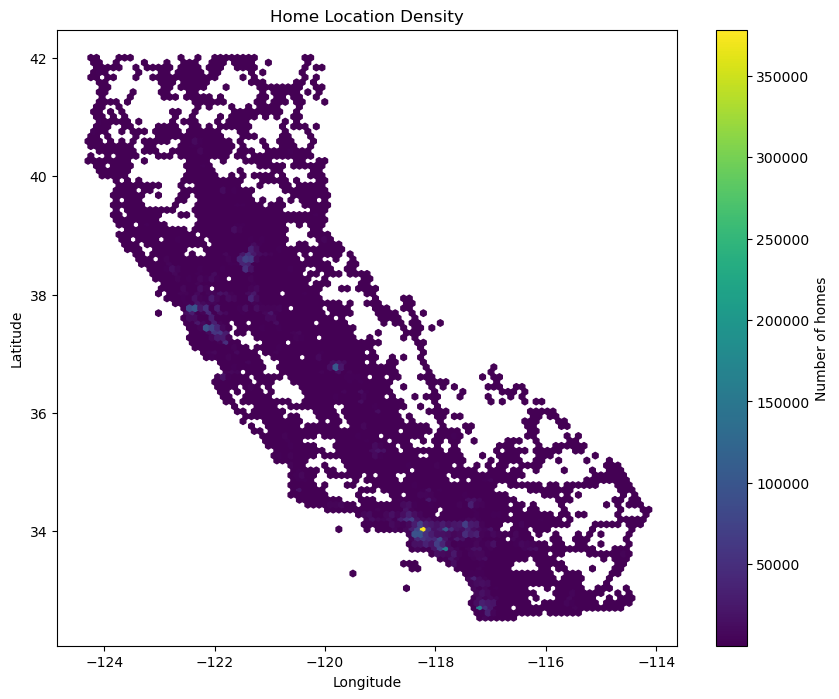

In [22]:
import matplotlib.pyplot as plt

# Extract latitude and longitude
latitudes = data['lat']
longitudes = data['lng']

# Create a hexbin plot
plt.figure(figsize=(10, 8))
hb = plt.hexbin(longitudes, latitudes, gridsize=100, cmap='viridis', mincnt=1)
plt.colorbar(hb, label='Number of homes')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Home Location Density')
plt.show()

In [23]:
import folium
from folium.plugins import HeatMap

# Create a sample of the data (reduce size for performance)
sampled_data = data.sample(100000)  # Using 100k points for visualization

# Create a Folium map centered on the average location
m = folium.Map(location=[sampled_data['lat'].mean(), sampled_data['lng'].mean()], zoom_start=6)

# Add a heatmap
heat_data = list(zip(sampled_data['lat'], sampled_data['lng']))
HeatMap(heat_data, radius=10).add_to(m)

# Save and display the map
m.save("home_locations_heatmap.html")
print("Heatmap saved as 'home_locations_heatmap.html'")

Heatmap saved as 'home_locations_heatmap.html'


In [24]:
m

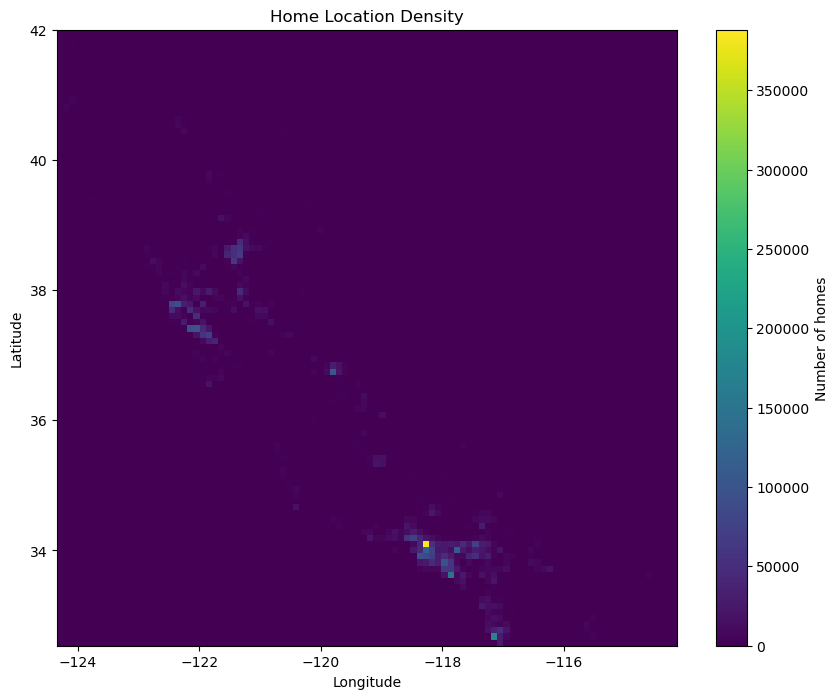

In [25]:
import numpy as np

# Plot a 2D histogram
plt.figure(figsize=(10, 8))
hist = plt.hist2d(longitudes, latitudes, bins=100, cmap='viridis')
plt.colorbar(hist[3], label='Number of homes')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Home Location Density')
plt.show()

# Dataset information

In [28]:
for file in daily_files:
    # Read the file
    df = pq.read_table(file).to_pandas()
    print(f"Columns in {file}: {df.columns}")
    break  # Only print for the first file to avoid clutter

Columns in /glade/derecho/scratch/jcelis/mobility/chunked_data/veraset_2024-03-14_PST_chunked.parquet: Index(['datetime', 'id_type', 'latitude', 'longitude', 'horizontal_accuracy'], dtype='object')


In [29]:
p=pq.ParquetFile(daily_files[11])

In [30]:
p.schema

required group field_id=-1 schema {
  optional int64 field_id=-1 datetime (Timestamp(isAdjustedToUTC=true, timeUnit=nanoseconds, is_from_converted_type=false, force_set_converted_type=false));
  optional binary field_id=-1 id_type (String);
  optional float field_id=-1 latitude;
  optional float field_id=-1 longitude;
  optional int32 field_id=-1 horizontal_accuracy (Int(bitWidth=16, isSigned=true));
  optional binary field_id=-1 caid (String);
}

In [ ]:
base_path_h = ‘/glade/derecho/scratch/jcelis/mobility/chunked_data’
key_file = ‘/glade/derecho/scratch/jcelis/mobility/chunked_data/id_row_group_key.parquet’
daily_files = sorted(glob(join(base_path_h, “veraset*“)))

base_path_h = ‘/glade/derecho/scratch/jcelis/mobility/chunked_data’
key_file = ‘/glade/derecho/scratch/jcelis/mobility/chunked_data/id_row_group_key.parquet’
daily_files = sorted(glob(join(base_path_h, “veraset*“)))
10:56
import pandas as pd
import numpy as np
from glob import glob
from os.path import join
from multiprocessing import Pool
import multiprocessing
import time
import pyarrow as pa
import pyarrow.parquet as pq
from skmob.core.trajectorydataframe import TrajDataFrame
from skmob.preprocessing import detection
from skmob.measures import individual
10:56
p = pq.ParquetFile(daily_files[11])
10:57
p.schema
10:57
p.read_row_group(25).to_pandas()
10:57
## load the metadata
meta = [pq.ParquetFile(x).metadata for x in daily_files]
10:57
def get_row_groups(row_group, files):
    “”" Read a specific row group across all files. “”"
    return pd.concat([pq.ParquetFile(f, metadata=m).read_row_group(row_group).to_pandas() for f, m in zip(files, meta)])
def get_row_group_trajectories(row_group, files):
    “”" Read the row group from all files and return a skmobility Trajectory DataFrame “”"
    df = get_row_groups(row_group, files)
    tdf = TrajDataFrame(df.reset_index(), latitude=‘latitude’, longitude=‘longitude’, datetime=‘datetime’, user_id=‘caid’)
    return tdf
def get_home_location(row_group, files):
    “”" Read the row group from all files and return the home location of each user. “”"
    tdf = get_row_group_trajectories(row_group, files)
    return individual.home_location(tdf, show_progress=False)
10:57
# Here we can test it with a single row group (1000 users) to grab all the data from March and April.
#%%time
row_group = 99
df = pd.concat([get_row_groups(99, daily_files)])
df
10:57
df.index.nunique()
10:58
#row_groups = np.arange(0, 1000) # grab the first thousand row groups (1 million users)
row_groups = np.arange(0, 7000) # grab the first thousand row groups (7 million users)
files = [daily_files] * len(row_groups)
args = [(rg, f) for rg, f in zip(row_groups, files)]
10:58
with Pool(processes=100) as pool:
    data = pd.concat(pool.starmap(get_home_location, args))
data
10:56
p = pq.ParquetFile(daily_files[11])
10:57
p.schema
10:57
p.read_row_group(25).to_pandas()
10:57
## load the metadata
meta = [pq.ParquetFile(x).metadata for x in daily_files]
10:57
def get_row_groups(row_group, files):
    “”" Read a specific row group across all files. “”"
    return pd.concat([pq.ParquetFile(f, metadata=m).read_row_group(row_group).to_pandas() for f, m in zip(files, meta)])
def get_row_group_trajectories(row_group, files):
    “”" Read the row group from all files and return a skmobility Trajectory DataFrame “”"
    df = get_row_groups(row_group, files)
    tdf = TrajDataFrame(df.reset_index(), latitude=‘latitude’, longitude=‘longitude’, datetime=‘datetime’, user_id=‘caid’)
    return tdf
def get_home_location(row_group, files):
    “”" Read the row group from all files and return the home location of each user. “”"
    tdf = get_row_group_trajectories(row_group, files)
    return individual.home_location(tdf, show_progress=False)
10:57
# Here we can test it with a single row group (1000 users) to grab all the data from March and April.
#%%time
row_group = 99
df = pd.concat([get_row_groups(99, daily_files)])
df
10:57
df.index.nunique()
10:58
#row_groups = np.arange(0, 1000) # grab the first thousand row groups (1 million users)
row_groups = np.arange(0, 7000) # grab the first thousand row groups (7 million users)
files = [daily_files] * len(row_groups)
args = [(rg, f) for rg, f in zip(row_groups, files)]
10:58
with Pool(processes=100) as pool:
    data = pd.concat(pool.starmap(get_home_location, args))
data